# Домашнє завдання до теми 12 «Метод k-means. Ієрархічний кластерний аналіз»

**Курс:** Вступ до машинного навчання (ІПЗ, 5 семестр)
**Студентка:** Вох Ірина

**Мета:** на наборі даних *Concrete* (рецептури бетону) створити нову ознаку `Components`, нормалізувати дані,
визначити оптимальну кількість кластерів за «правилом ліктя» (`KElbowVisualizer`), виконати кластеризацію методом
k-середніх і побудувати описовий «звіт» по кластерах (медіани ознак + кількість рецептур), після чого зробити висновки
про фактори, що впливають на міцність бетону.

**План роботи:**
1. Імпорт бібліотек.
2. Завантаження набору даних Concrete (як у темі 10).
3. Короткий огляд даних.
4. Створення ознаки `Components` прийомом підрахунку кількості.
5. Нормалізація даних (`StandardScaler`).
6. Визначення оптимальної кількості кластерів (`KElbowVisualizer`).
7. Кластеризація методом k-середніх та отримання міток.
8. Візуалізація та оцінка якості кластеризації (додатково).
9. Звіт по кластерах: медіани ознак (на оригінальних даних) + кількість об'єктів.
10. Аналіз звіту та висновки.

## 1. Імпорт бібліотек

In [1]:
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram
from yellowbrick.cluster import KElbowVisualizer

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 200)

## 2. Завантаження набору даних

Набір даних Concrete завантажуємо так само, як у розділі «Поширені прийоми генерації ознак. Математичні перетворення»
теми 10: з об'єкта-словника, збереженого у файлі `mod_05_topic_10_various_data.pkl`.

In [2]:
with open('../datasets/mod_05_topic_10_various_data.pkl', 'rb') as fl:
    datasets = pickle.load(fl)

concrete = datasets['concrete'].copy()
concrete.head()

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,CompressiveStrength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## 3. Огляд даних

In [3]:
print('Розмір набору:', concrete.shape)
concrete.info()

Розмір набору: (1030, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Cement               1030 non-null   float64
 1   BlastFurnaceSlag     1030 non-null   float64
 2   FlyAsh               1030 non-null   float64
 3   Water                1030 non-null   float64
 4   Superplasticizer     1030 non-null   float64
 5   CoarseAggregate      1030 non-null   float64
 6   FineAggregate        1030 non-null   float64
 7   Age                  1030 non-null   int64  
 8   CompressiveStrength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [4]:
print('Пропущені значення:\n', concrete.isna().sum(), sep='')
print('\nКількість повних дублікатів рядків:', concrete.duplicated().sum())

Пропущені значення:
Cement                 0
BlastFurnaceSlag       0
FlyAsh                 0
Water                  0
Superplasticizer       0
CoarseAggregate        0
FineAggregate          0
Age                    0
CompressiveStrength    0
dtype: int64

Кількість повних дублікатів рядків: 25


In [5]:
concrete.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
BlastFurnaceSlag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
FlyAsh,1030.0,54.19,64.00,0.00,0.00,0.00,118.30,200.1
Water,1030.0,181.57,21.35,121.80,164.90,185.00,192.00,247.0
Superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.40,10.20,32.2
CoarseAggregate,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
FineAggregate,1030.0,773.58,80.18,594.00,730.95,779.50,824.00,992.6
Age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
CompressiveStrength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


Набір містить 1030 рецептур бетону: вміст 7 складових (кг/м³), вік зразка `Age` (дні) та цільову характеристику
`CompressiveStrength` (міцність на стиск, МПа). Усі ознаки числові, пропусків немає. Дублікати (якщо є) — це
однакові рецептури, випробувані повторно; вони є легітимними спостереженнями, тож ми їх не видаляємо.
Ознаки мають дуже різні масштаби (наприклад, `CoarseAggregate` ~1000, `Superplasticizer` ~6), тому перед
кластеризацією (алгоритм k-means спирається на евклідову відстань) їх обов'язково треба нормалізувати.

## 4. Нова ознака `Components` (прийом підрахунку кількості)

Частина рецептур не містить окремих складових (їх вміст дорівнює 0). Перетворимо числові ознаки складових на булеві
методом `gt(0)` і підсумуємо по рядку — отримаємо кількість задіяних складових у кожній рецептурі.

In [6]:
components = ['Cement',
              'BlastFurnaceSlag',
              'FlyAsh',
              'Water',
              'Superplasticizer',
              'CoarseAggregate',
              'FineAggregate']

concrete['Components'] = concrete[components].gt(0).sum(axis=1)

concrete[components + ['Components']].head(10)

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Components
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,5
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,5
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,5
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,5
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,5
5,266.0,114.0,0.0,228.0,0.0,932.0,670.0,5
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,5
7,380.0,95.0,0.0,228.0,0.0,932.0,594.0,5
8,266.0,114.0,0.0,228.0,0.0,932.0,670.0,5
9,475.0,0.0,0.0,228.0,0.0,932.0,594.0,4


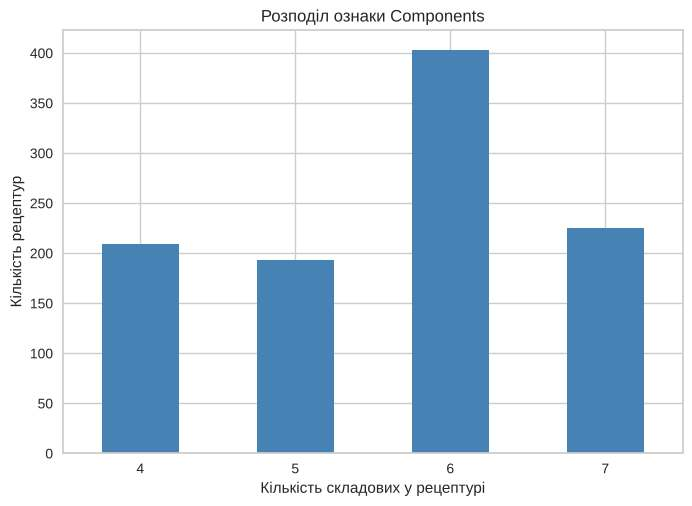

In [7]:
ax = concrete['Components'].value_counts().sort_index().plot.bar(rot=0, color='steelblue')
ax.set_xlabel('Кількість складових у рецептурі')
ax.set_ylabel('Кількість рецептур')
ax.set_title('Розподіл ознаки Components')
plt.show()

Рецептури містять від 4 до 7 складових. Цемент, вода та обидва заповнювачі присутні завжди, тож мінімум — 4
(«базовий» бетон без добавок), а різниця між рецептурами визначається наявністю шлаку, золи-винесення та
суперпластифікатора.

## 5. Нормалізація даних

Нормалізуємо всі ознаки (включно з новою `Components`) за допомогою `StandardScaler` (середнє 0, стандартне
відхилення 1). Оригінальний датафрейм `concrete` залишаємо без змін — він знадобиться для побудови звіту.

In [8]:
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(concrete),
                 columns=concrete.columns,
                 index=concrete.index)

X.describe().T[['mean', 'std']].round(3)

,mean,std
Cement,-0.0,1.0
BlastFurnaceSlag,-0.0,1.0
FlyAsh,-0.0,1.0
Water,-0.0,1.0
Superplasticizer,-0.0,1.0
CoarseAggregate,0.0,1.0
FineAggregate,-0.0,1.0
Age,0.0,1.0
CompressiveStrength,-0.0,1.0
Components,0.0,1.0


## 6. Визначення оптимальної кількості кластерів (`KElbowVisualizer`)

Виконуємо серію кластеризацій k-means для k від 2 до 9 та будуємо графік залежності сумарної міри щільності
(distortion — сума квадратів відстаней до центроїдів) від k. Оптимальне k визначаємо за «правилом ліктя».

> **Технічна примітка.** У новіших версіях scikit-learn (≥ 1.6) змінився механізм визначення типу моделі, і
> `yellowbrick` 1.5 перестав розпізнавати `KMeans` як кластеризатор. Тому для візуалізатора використовуємо
> тонкий підклас `KMeans` з явно заданим атрибутом `_estimator_type = 'clusterer'`. Алгоритм і параметри при цьому
> не змінюються; у середовищі курсу код працює так само.

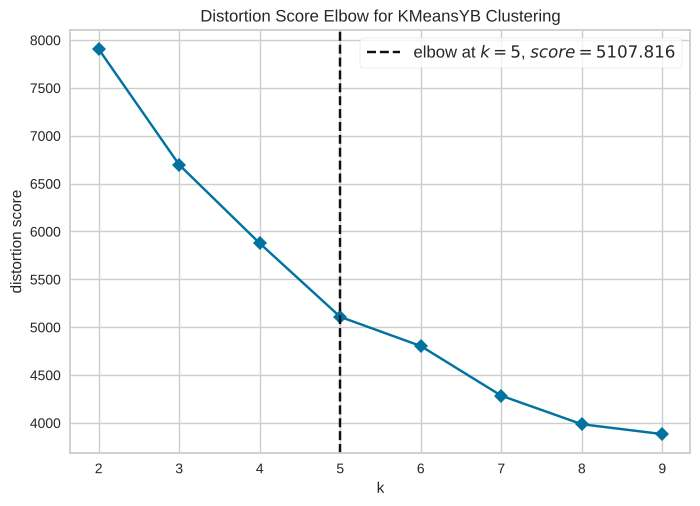

Оптимальна кількість кластерів за правилом ліктя: 5


In [9]:
class KMeansYB(KMeans):
    # сумісність yellowbrick 1.5 з новими версіями scikit-learn
    _estimator_type = 'clusterer'


model_kmn = KMeansYB(random_state=42)

visualizer = KElbowVisualizer(
    model_kmn,
    k=(2, 10),
    timings=False)

visualizer.fit(X)
visualizer.show()

n_clusters = visualizer.elbow_value_
print('Оптимальна кількість кластерів за правилом ліктя:', n_clusters)

In [10]:
pd.Series(visualizer.k_scores_, index=range(2, 10), name='distortion').round(1).to_frame().T

,2,3,4,5,6,7,8,9
distortion,7905.7,6696.8,5876.6,5107.8,4803.2,4284.2,3986.1,3882.8


## 7. Кластеризація методом k-середніх

Проводимо кластеризацію з кількістю кластерів, визначеною на попередньому кроці, і отримуємо мітки.

In [11]:
k_means = KMeans(n_clusters=n_clusters, random_state=42)
labels = k_means.fit_predict(X)

print('Мітки перших 20 об\'єктів:', labels[:20])
pd.Series(labels).value_counts().sort_index().rename('Count').to_frame().T

Мітки перших 20 об'єктів: [0 4 2 2 2 1 2 1 1 4 1 1 2 1 1 4 1 2 2 2]


,0,1,2,3,4
Count,198,177,48,406,201


## 8. Візуалізація та оцінка якості кластеризації (додатково)

Щоб переконатися, що кластери змістовні, обчислимо коефіцієнт силуету для різних k та відобразимо кластери в
просторі двох перших головних компонент (PCA, тема 11).

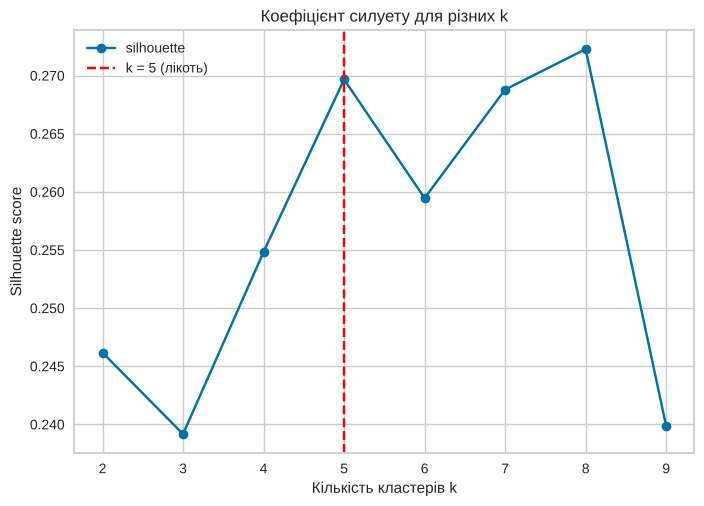

Silhouette score для k = 5: 0.270


In [12]:
sil = {k: silhouette_score(X, KMeans(n_clusters=k, random_state=42).fit_predict(X))
       for k in range(2, 10)}
sil = pd.Series(sil, name='silhouette')

ax = sil.plot(marker='o')
ax.axvline(n_clusters, ls='--', color='red', label=f'k = {n_clusters} (лікоть)')
ax.set_xlabel('Кількість кластерів k')
ax.set_ylabel('Silhouette score')
ax.set_title('Коефіцієнт силуету для різних k')
ax.legend()
plt.show()

print(f'Silhouette score для k = {n_clusters}: {sil[n_clusters]:.3f}')

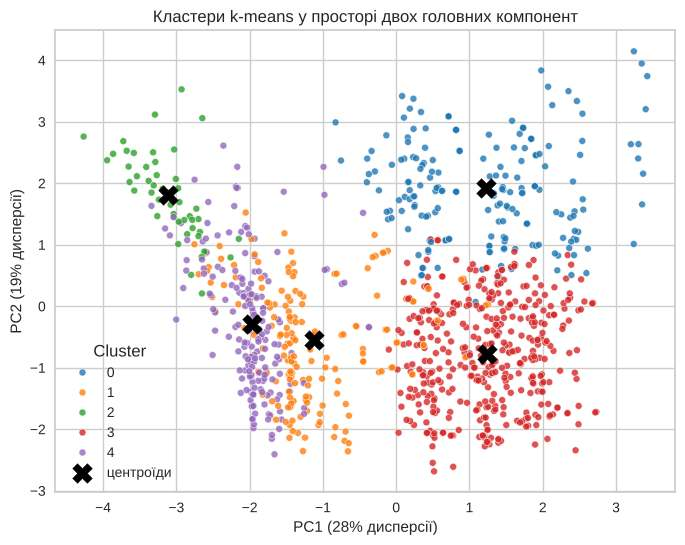

In [13]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels,
                palette='tab10', s=25, alpha=0.8, ax=ax)
centers_pca = pca.transform(pd.DataFrame(k_means.cluster_centers_, columns=X.columns))
ax.scatter(centers_pca[:, 0], centers_pca[:, 1], c='black', marker='X', s=200, label='центроїди')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} дисперсії)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} дисперсії)')
ax.set_title('Кластери k-means у просторі двох головних компонент')
ax.legend(title='Cluster')
plt.show()

Для порівняння побудуємо також ієрархічну структуру кластерів за допомогою `AgglomerativeClustering`
(метод Варда) та дендрограму — так, як це показано у практичній частині теми 12.

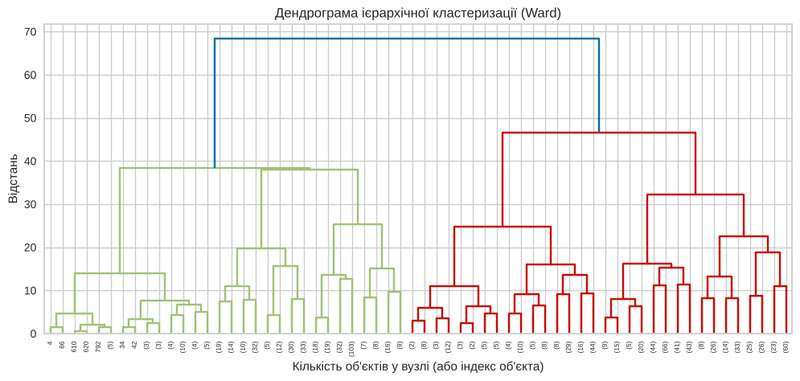

Adjusted Rand Index (k-means vs ієрархічна, k = 5): 0.766


In [14]:
def plot_dendrogram(model, **kwargs):

    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]).astype(float)

    dendrogram(linkage_matrix, **kwargs)


model_agg = AgglomerativeClustering(distance_threshold=0,
                                    n_clusters=None,
                                    linkage='ward')
model_agg = model_agg.fit(X)

plt.figure(figsize=(12, 5))
plot_dendrogram(model_agg, truncate_mode='level', p=5)
plt.title('Дендрограма ієрархічної кластеризації (Ward)')
plt.xlabel('Кількість об\'єктів у вузлі (або індекс об\'єкта)')
plt.ylabel('Відстань')
plt.show()

agg_labels = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward').fit_predict(X)
print(f'Adjusted Rand Index (k-means vs ієрархічна, k = {n_clusters}): '
      f'{adjusted_rand_score(labels, agg_labels):.3f}')

## 9. Звіт по кластерах

Для звіту використовуємо **оригінальні (ненормалізовані) дані**: додаємо мітки кластерів, групуємо методом
`groupby` і рахуємо медіани всіх ознак (включно з `Components`), а потім додаємо кількість рецептур у кожному кластері.

In [15]:
report = (concrete
          .assign(Cluster=labels)
          .groupby('Cluster')
          .median())

report['Count'] = (pd.Series(labels, index=concrete.index)
                   .value_counts()
                   .sort_index())

report.round(1)

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,CompressiveStrength,Components,Count
Cluster,,,,,,,,,,,
0,382.2,117.2,0.0,162.0,11.6,936.0,781.5,28.0,56.6,6.0,198
1,186.2,183.4,0.0,192.0,0.0,965.4,748.5,28.0,27.0,5.0,177
2,340.5,47.5,0.0,228.0,0.0,932.0,670.0,270.0,43.7,5.0,48
3,213.7,0.0,121.6,175.3,8.2,1002.9,780.6,28.0,32.2,6.0,406
4,339.0,0.0,0.0,192.0,0.0,1012.0,784.0,28.0,26.8,4.0,201


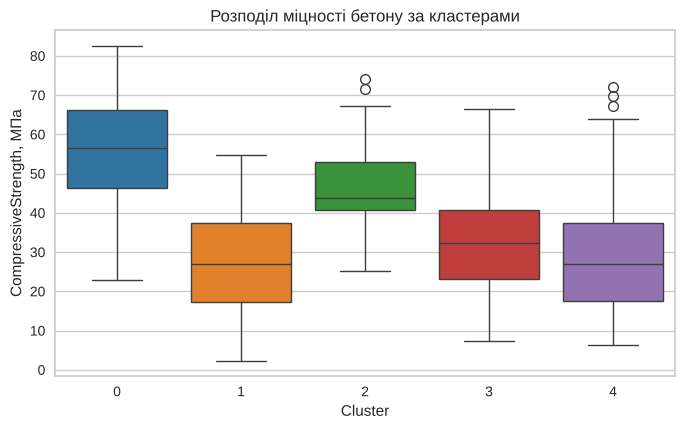

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(x=labels, y=concrete['CompressiveStrength'], palette='tab10', ax=ax)
ax.set_xlabel('Cluster')
ax.set_ylabel('CompressiveStrength, МПа')
ax.set_title('Розподіл міцності бетону за кластерами')
plt.show()

Додатково (для інтерпретації) порахуємо медіанне водоцементне відношення та частку рецептур із
суперпластифікатором у кожному кластері — це класичні технологічні фактори міцності бетону.

In [17]:
extra = (concrete
         .assign(Cluster=labels,
                 WaterCementRatio=concrete['Water'] / concrete['Cement'],
                 HasSuperplasticizer=concrete['Superplasticizer'].gt(0))
         .groupby('Cluster')
         .agg(WaterCementRatio=('WaterCementRatio', 'median'),
              ShareWithSuperplasticizer=('HasSuperplasticizer', 'mean'),
              MeanStrength=('CompressiveStrength', 'mean')))

extra.round(2)

,WaterCementRatio,ShareWithSuperplasticizer,MeanStrength
Cluster,,,
0,0.41,0.99,56.14
1,1.04,0.25,26.83
2,0.62,0.00,46.67
3,0.78,0.99,32.10
4,0.58,0.04,28.62


## 10. Аналіз звіту та висновки

In [18]:
for c, row in report.sort_values('CompressiveStrength', ascending=False).iterrows():
    print(f"Кластер {c}: {int(row['Count'])} рецептур, медіанна міцність {row['CompressiveStrength']:.1f} МПа, "
          f"цемент {row['Cement']:.0f}, вода {row['Water']:.0f}, суперпластифікатор {row['Superplasticizer']:.1f}, "
          f"вік {row['Age']:.0f} дн., складових {row['Components']:.0f}")

Кластер 0: 198 рецептур, медіанна міцність 56.6 МПа, цемент 382, вода 162, суперпластифікатор 11.6, вік 28 дн., складових 6
Кластер 2: 48 рецептур, медіанна міцність 43.7 МПа, цемент 340, вода 228, суперпластифікатор 0.0, вік 270 дн., складових 5
Кластер 3: 406 рецептур, медіанна міцність 32.2 МПа, цемент 214, вода 175, суперпластифікатор 8.2, вік 28 дн., складових 6
Кластер 1: 177 рецептур, медіанна міцність 27.0 МПа, цемент 186, вода 192, суперпластифікатор 0.0, вік 28 дн., складових 5
Кластер 4: 201 рецептур, медіанна міцність 26.9 МПа, цемент 339, вода 192, суперпластифікатор 0.0, вік 28 дн., складових 4


### Висновки

**Щодо процесу.** Набір Concrete (1030 рецептур, без пропусків) доповнено ознакою `Components` (4–7 складових у
рецептурі), дані нормалізовано `StandardScaler`. За «правилом ліктя» (`KElbowVisualizer`, k = 2…9) оптимальна
кількість кластерів — **5**; коефіцієнт силуету для k = 5 (≈ 0.27) є одним із найвищих серед розглянутих k, тобто вибір
узгоджується з альтернативною метрикою. Кластери перекриваються (силует < 0.5 — типово для «неперервних» рецептурних
даних), але мають чітку технологічну інтерпретацію. Ієрархічна кластеризація (Ward) дає подібне, хоча й не
ідентичне, розбиття (ARI ≈ 0.77), що підтверджує стійкість знайденої структури.

**Опис кластерів (за медіанами звіту):**

| Кластер | Рецептур | Характеристика | Медіанна міцність |
|---|---|---|---|
| 0 | 198 | Багато цементу (~382) і шлаку, **найменше води (162)**, **багато суперпластифікатора (~11.6)**, 6 складових | **≈ 56.6 МПа — найміцніший** |
| 2 | 48 | Найменший кластер: **«старі» зразки (вік ~270 днів)**, багато води (228), без добавок | ≈ 43.7 МПа |
| 3 | 406 | Найбільший кластер: помірно цементу (~214), **зола-винесення (~122)** + суперпластифікатор, 6 складових | ≈ 32.2 МПа |
| 1 | 177 | Мало цементу (~186), **багато шлаку (~183)**, без суперпластифікатора | ≈ 27.0 МПа |
| 4 | 201 | «Базовий» бетон з **4 складових** (лише цемент, вода, заповнювачі), цементу ~339, води 192 | ≈ 26.9 МПа |

**Фактори, що суттєво впливають на міцність бетону:**
1. **Водоцементне відношення (В/Ц).** Найміцніший кластер 0 має найнижче медіанне В/Ц (≈ 0.41) і найменше води,
   а найслабший кластер 1 — найвище (≈ 1.04). Кластер 4 містить багато цементу (~339), але через більшу кількість води
   (В/Ц ≈ 0.58) і відсутність добавок його міцність (≈ 26.9 МПа) удвічі нижча, ніж у кластері 0, — сама кількість
   цементу не гарантує міцності.
2. **Суперпластифікатор** дозволяє зменшити кількість води без втрати рухливості суміші; кластери з ним (0, 3) у
   середньому міцніші за аналогічні без нього.
3. **Вік зразка.** Кластер 2 виділився переважно за віком: попри високий вміст води, тривале тверднення (~270 днів)
   забезпечує другу за величиною міцність. Тобто `Age` — важливий фактор, який треба враховувати при порівнянні рецептур.
4. **Мінеральні добавки (шлак, зола)** частково замінюють цемент: рецептури з високою часткою шлаку при малій
   кількості цементу (кластер 1) мають низьку міцність у віці 28 днів.
5. **Кількість складових (`Components`)**: «прості» 4-компонентні рецептури (кластер 4) — серед найменш міцних, а
   найміцніший кластер — 6-компонентний. Отже, нова ознака є інформативною для подальшого моделювання.

**Практичне значення.** Отримані кластери можна використати як додаткову категоріальну ознаку (або для побудови
окремих моделей) у задачі прогнозування `CompressiveStrength`, а також для пошуку «типових» рецептур високоміцного
бетону (кластер 0: багато цементу, мало води, суперпластифікатор).